Bài 1: Đọc một tấm ảnh

In [ ]:
from google.colab import files
import cv2

uploaded = files.upload()

Saving cat.jpg to cat.jpg


Size:  (554, 554, 3)
Data type:  uint8
Dimension: 3
Highest pixel value:  246
Lowest pixel value:  0


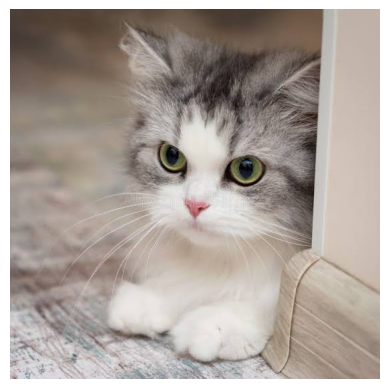

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

image = cv2.imread("cat.jpg")
print("Size: ", image.shape)
print("Data type: ", image.dtype)
print("Dimension:", image.ndim)
print("Highest pixel value: ", image.max())
print("Lowest pixel value: ",  image.min())

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(image)
plt.axis("off")
plt.show()

In [ ]:
# Ảnh màu 3 kênh => k = 3*8 = 24 bit/pixel
k = image.ndim * 8
# Dung lượng ảnh:
b =  1282 * 960 * k
print("Capacity: ", b, "bit")
print((b/8)/1000000, "mb" )

Capacity:  29537280 bit
3.69216 mb


Bài 2: Lấy mẫu - thu nhỏ ảnh

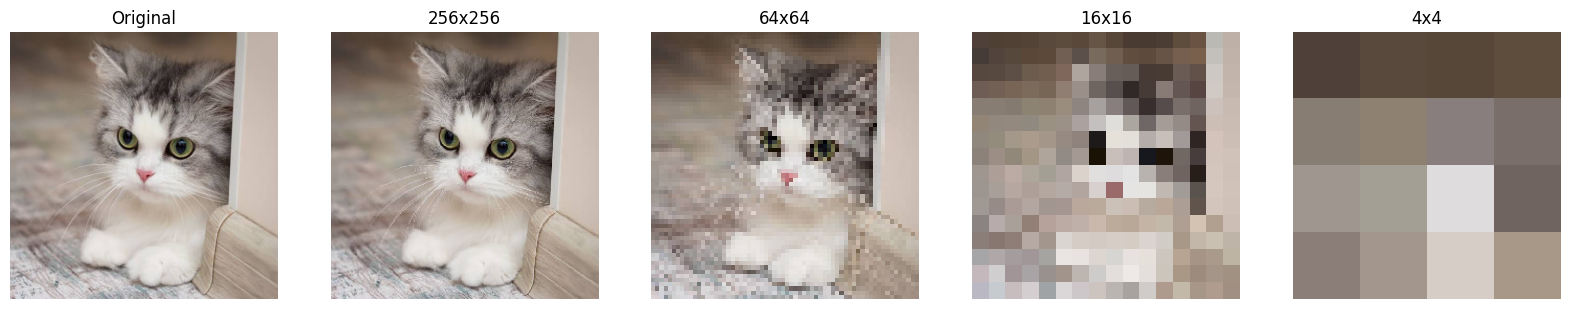

In [ ]:
image_resize_256x256 = cv2.resize(image,
                            (256,256),
                            interpolation=cv2.INTER_NEAREST)

image_resize_64x64 = cv2.resize(image,
                            (64,64),
                            interpolation=cv2.INTER_NEAREST)

image_resize_16x16 = cv2.resize(image,
                            (16,16),
                            interpolation=cv2.INTER_NEAREST)

image_resize_4x4 = cv2.resize(image,
                            (4,4),
                            interpolation=cv2.INTER_NEAREST)

plt.figure(figsize=(20, 4))

plt.subplot(1, 5, 1)
plt.imshow(image)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 5, 2)
plt.imshow(image_resize_256x256)
plt.title("256x256")
plt.axis("off")

plt.subplot(1, 5, 3)
plt.imshow(image_resize_64x64)
plt.title("64x64")
plt.axis("off")

plt.subplot(1, 5, 4)
plt.imshow(image_resize_16x16)
plt.title("16x16")
plt.axis("off")

plt.subplot(1, 5, 5)
plt.imshow(image_resize_4x4)
plt.title("4x4")
plt.axis("off")

plt.show()

16x16 Thì không còn nhận ra được ảnh

Bài 3: Lượng tử hóa

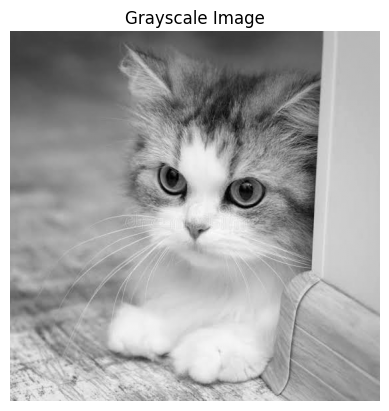

In [ ]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

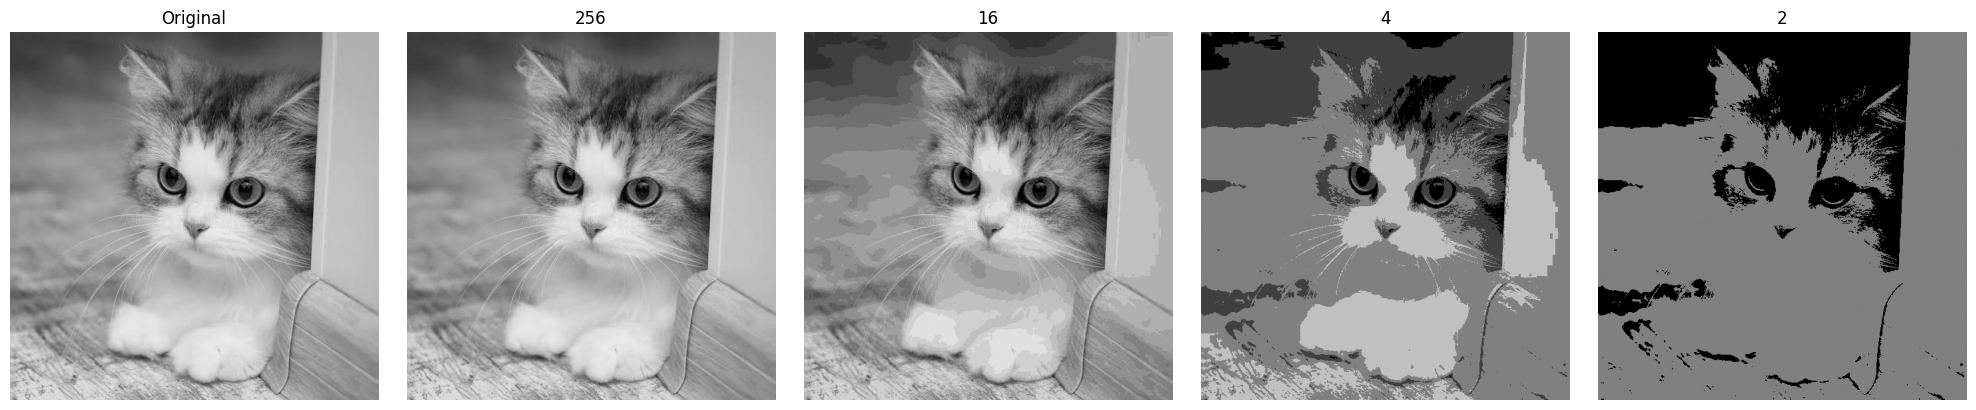

In [ ]:
quantized_256 = (np.floor(gray / (256/256)) * (256/256)).astype(np.uint8)
quantized_16  = (np.floor(gray / (256/16))  * (256/16)).astype(np.uint8)
quantized_4   = (np.floor(gray / (256/4))   * (256/4)).astype(np.uint8)
quantized_2   = (np.floor(gray / (256/2))   * (256/2)).astype(np.uint8)

plt.figure(figsize=(20, 4))

plt.subplot(1, 5, 1)
plt.imshow(gray, cmap="gray", vmin=0, vmax=255)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 5, 2)
plt.imshow(quantized_256, cmap="gray", vmin=0, vmax=255)
plt.title("256")
plt.axis("off")

plt.subplot(1, 5, 3)
plt.imshow(quantized_16, cmap="gray", vmin=0, vmax=255)
plt.title("16")
plt.axis("off")

plt.subplot(1, 5, 4)
plt.imshow(quantized_4, cmap="gray", vmin=0, vmax=255)
plt.title("4")
plt.axis("off")

plt.subplot(1, 5, 5)
plt.imshow(quantized_2, cmap="gray", vmin=0, vmax=255)
plt.title("2")
plt.axis("off")

plt.tight_layout()
plt.show()


Múc xám 16 bắt đầu xuất hiện mảng loang có viền giả

Bài 4

$$
A=\begin{bmatrix}
0 & 1 & 1\\
0 & 2 & 0\\
0 & 0 & 1
\end{bmatrix}
$$

Dọc: (1,2), (2,1), (2,3), (3,2) Hợp lệ: (1,2)

Chéo: (1,1),(1,3),(3,1),(3,3) Hợp lệ: (3,3), (1,3)

N8(p): (1,2), (3,3), (1,3)

Đường ngắn nhất: 2 step (1,3) -> (2,2) -> (3,3)

m-step: (1,3) -> (1,2) -> (2,2) -> (3,3)
